# **Durability — RUL DATASET GENERATION**

## Prerequisite

Run [`01_generate_dataset.ipynb`](01_generate_dataset.ipynb) $\to$
[`02_train_pce.ipynb`](02_train_pce.ipynb) $\to$
[`03_generate_dataset_nn.ipynb`](03_generate_dataset_nn.ipynb) $\to$
[`04_train_nn.ipynb`](04_train_nn.ipynb) first — this notebook loads the global NN
(`lambda 1`/`lambda 2` vs. `(fck, rh, cov, t)`) that stage 4 writes.

## What this notebook does

Fixes a single design point `(fck, rh, cov)` and sweeps a list of time steps through the trained
NN, giving $\lambda_1(t)$ and $\lambda_2(t)$ at each one **directly** — no need to pick a
per-time-step PCE first. $\lambda_3$ and $\lambda_4$ barely move across the design space, which is
why they were never modelled by the NN — they're fixed here instead, to a value you set or, by
default, the mean over the NN's own training dataset.

At each time step, `generate_rul_dataset_durability` builds a `GlamFKML(lam1, lam2, lam3, lam4)` and
draws `n_glam_samples` Monte Carlo realisations of the state limit function $g$ = cover −
carbonation depth — the raw material for the spaghetti plot and the RUL analysis in
[`05_plot_rul_analysis.ipynb`](05_plot_rul_analysis.ipynb).

## 1. Libraries

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import dill
import numpy as np
import pandas as pd

import importlib
import functions

# Recarrega functions.py ao executar esta celula novamente.
importlib.reload(functions)
from functions import *

## 2. Config

`n_latent_samples`, `installation_year`, `co2_scenario`, `cement_type` and `exposure_conditions`
must match [`04_train_nn.ipynb`](04_train_nn.ipynb) — it names the NN model files being loaded.

`lambda3_fixed`/`lambda4_fixed` left as `None` fall back to the mean of `lambda 3`/`lambda 4` over
the NN training dataset; set either explicitly to override.

In [2]:
n_latent_samples    = 2500      # must match stage 4 — it names the NN model files being loaded
installation_year   = 1980
co2_scenario        = "SSP2-4.5"
cement_type         = 3
exposure_conditions = 2

fck_fixed = 25.0   # fixed compressive strength for the whole sweep (MPa)
rh_fixed  = 55.0   # fixed relative humidity for the whole sweep (%)
cov_fixed = 25.0   # fixed cover for the whole sweep (mm)

t_total = 100         # total project service life (years)
t_maintenance = 40    # maintenance interval (cover reset)
pts_per_segment = 10  # point resolution for each individual curve

lambda3_fixed = 0.198312   # None = mean of lambda 3 over the NN training dataset
lambda4_fixed = 0.130039   # None = mean of lambda 4 over the NN training dataset

n_glam_samples = 50000   # Monte Carlo samples drawn from the GLD at each time step

print(f"Sweeping t = 0..{t_total} years with maintenance every {t_maintenance} years at fck={fck_fixed}, rh={rh_fixed}, cov={cov_fixed}")

# Arquivos de entrada usados para gerar o dataset de RUL.
input_dir = Path('.').resolve()
input_tag = f'install_{installation_year}_cement_{cement_type}_exposure_{exposure_conditions}_co2_{co2_scenario}'
rul_input_files = {
    'Modelo NN - lambda 1': input_dir / f'{n_latent_samples}_nn_lambda_1_model_durability_{input_tag}.pkl',
    'Modelo NN - lambda 2': input_dir / f'{n_latent_samples}_nn_lambda_2_model_durability_{input_tag}.pkl',
    'Scaler NN': input_dir / f'{n_latent_samples}_nn_scaler_durability_{input_tag}.pkl',
}
if lambda3_fixed is None or lambda4_fixed is None:
    rul_input_files['Dataset NN - medias de lambda 3/4'] = input_dir / f'{n_latent_samples}_dataset_nn_durability_{input_tag}.pkl'

print('\n[RUL] Arquivos que serao carregados:')
for label, path in rul_input_files.items():
    status = 'ENCONTRADO' if path.is_file() else 'AUSENTE'
    print(f'  [{status}] {label}: {path}')
if lambda3_fixed is not None and lambda4_fixed is not None:
    print('[RUL] Lambda 3/4 definidos acima; o dataset NN nao sera carregado.')


Sweeping t = 0..100 years with maintenance every 40 years at fck=25.0, rh=55.0, cov=25.0


## 3. Predict lambda 1/2, fix lambda 3/4, and draw the GLD samples

In [ ]:
import pandas as pd
import numpy as np

print("="*60)
print("GERANDO DATASET COM OTIMIZADOR DE MANUTENÇÃO (THRESHOLD)")
print("="*60)

# Parâmetros do Otimizador
p_fail_threshold = 0.20  # Gatilho: 20% da massa de probabilidade abaixo da curva
g_limit = 0.0            # Critério de falha: cobrimento <= 0 mm

current_year = 0
all_lambda_dfs = []
all_samples = []
maintenance_history = []

while current_year < t_total:
    max_duration = t_total - current_year
    
    # Gera pontos com resolução anual para o concreto novo
    segment_times = np.linspace(0, max_duration, int(max_duration) + 1, endpoint=True)
    
    print(f"\n--- Iniciando ciclo a partir do ano {current_year:.1f} ---")
    
    result = generate_rul_dataset_durability(
        fck=fck_fixed,
        rh=rh_fixed,
        cov=cov_fixed,
        times=segment_times,
        n_latent_samples=n_latent_samples,
        installation_year=installation_year,
        cement_type=cement_type,
        exposure_conditions=exposure_conditions,
        co2_scenario=co2_scenario,
        lambda3_fixed=lambda3_fixed,
        lambda4_fixed=lambda4_fixed,
        n_glam_samples=n_glam_samples,
        input_dir=input_dir,
        output_dir='.'
    )
    
    df_temp = result['lambda_df'].copy()
    samples_temp = result['samples']
    
    # Calcula a probabilidade de falha P(g <= limit) para cada passo de tempo
    p_fail = (samples_temp <= g_limit).mean(axis=0)
    
    # Verifica onde o threshold de 20% é ultrapassado
    cross_indices = np.where(p_fail >= p_fail_threshold)[0]
    
    if len(cross_indices) > 0:
        # O limite foi atingido
        idx_cross = cross_indices[0]
        duration_until_repair = segment_times[idx_cross]
        
        # Prevenção contra loop infinito caso falhe no ano zero
        if duration_until_repair == 0:
            duration_until_repair = 1
            idx_cross = 1
            
        print(f" -> Manutenção disparada! Estrutura falhou em {duration_until_repair:.1f} anos locais.")
        print(f" -> Ano Global da Intervenção: {current_year + duration_until_repair:.1f} | Risco: {p_fail[idx_cross]:.2%}")
        
        # Recorta os dados apenas até o ano da manutenção
        df_slice = df_temp.iloc[:idx_cross+1].copy()
        samples_slice = samples_temp[:, :idx_cross+1]
        
        # Translada o tempo local para o tempo global da obra
        df_slice['Time (years)'] = df_slice['Time (years)'] + current_year
        all_lambda_dfs.append(df_slice)
        all_samples.append(samples_slice)
        
        # Atualiza o tempo atual e regista a manutenção
        current_year += duration_until_repair
        maintenance_history.append(current_year)
        
    else:
        # A estrutura sobreviveu até o final do projeto sem ultrapassar o threshold
        print(f" -> Estrutura chegou ao fim do projeto (100 anos) sem novas manutenções.")
        
        df_temp['Time (years)'] = df_temp['Time (years)'] + current_year
        all_lambda_dfs.append(df_temp)
        all_samples.append(samples_temp)
        break

# Concatena os resultados otimizados
final_lambda_df = pd.concat(all_lambda_dfs, ignore_index=True)
final_samples = np.hstack(all_samples)

print(f"\nShape final dos samples: {final_samples.shape} (n_glam_samples x total_time_steps)")
print(f"Anos das intervenções de manutenção: {maintenance_history}")

GERANDO DATASET COM OTIMIZADOR DE MANUTENÇÃO (THRESHOLD)

--- Iniciando ciclo a partir do ano 0.0 ---

----------------------------------------
GENERATING RUL DATASET AT fck=25.0, rh=55.0, cov=25.0
----------------------------------------
  lambda 3 fixed at 0.1983, lambda 4 fixed at 0.1300
  t = 0.0: lambda 1 = 25.018, lambda 2 = 0.392, sample mean = 25.147, sample std = 3.587
  t = 1.0: lambda 1 = 24.468, lambda 2 = 0.384, sample mean = 24.600, sample std = 3.661
  t = 2.0: lambda 1 = 23.918, lambda 2 = 0.377, sample mean = 24.052, sample std = 3.733
  t = 3.0: lambda 1 = 23.330, lambda 2 = 0.370, sample mean = 23.467, sample std = 3.807
  t = 4.0: lambda 1 = 22.651, lambda 2 = 0.362, sample mean = 22.790, sample std = 3.885
  t = 5.0: lambda 1 = 21.972, lambda 2 = 0.355, sample mean = 22.114, sample std = 3.964
  t = 6.0: lambda 1 = 21.293, lambda 2 = 0.348, sample mean = 21.438, sample std = 4.038
  t = 7.0: lambda 1 = 20.613, lambda 2 = 0.344, sample mean = 20.760, sample std = 4.

## 4. Sanity check

In [11]:
summary = pd.DataFrame({
    'Time (years)': final_lambda_df['Time (years)'].values,
    'Sample mean':  final_samples.mean(axis=0),
    'Sample std':   final_samples.std(axis=0),
    'P(g <= 0)':    (final_samples <= 0).mean(axis=0),
})

summary

,Time (years),Sample mean,Sample std,P(g <= 0)
0,0.0,25.146943,3.587082,0.00000
1,1.0,24.599576,3.661108,0.00000
2,2.0,24.052127,3.732858,0.00000
3,3.0,23.466944,3.807477,0.00000
4,4.0,22.790493,3.885140,0.00000
...,...,...,...,...
98,96.0,8.088778,5.346765,0.06160
99,97.0,7.711241,5.423424,0.07480
100,98.0,7.335645,5.501720,0.08944
101,99.0,6.999788,5.572190,0.10368


In [12]:
summary_5mm = pd.DataFrame({
    'Time (years)': final_lambda_df['Time (years)'].values,
    'Sample mean':  final_samples.mean(axis=0),
    'Sample std':   final_samples.std(axis=0),
    'P(g <= 5)':    (final_samples <= 5.0).mean(axis=0),
})

summary_5mm

,Time (years),Sample mean,Sample std,P(g <= 5)
0,0.0,25.146943,3.587082,0.00000
1,1.0,24.599576,3.661108,0.00000
2,2.0,24.052127,3.732858,0.00000
3,3.0,23.466944,3.807477,0.00000
4,4.0,22.790493,3.885140,0.00000
...,...,...,...,...
98,96.0,8.088778,5.346765,0.29010
99,97.0,7.711241,5.423424,0.31766
100,98.0,7.335645,5.501720,0.34524
101,99.0,6.999788,5.572190,0.36986


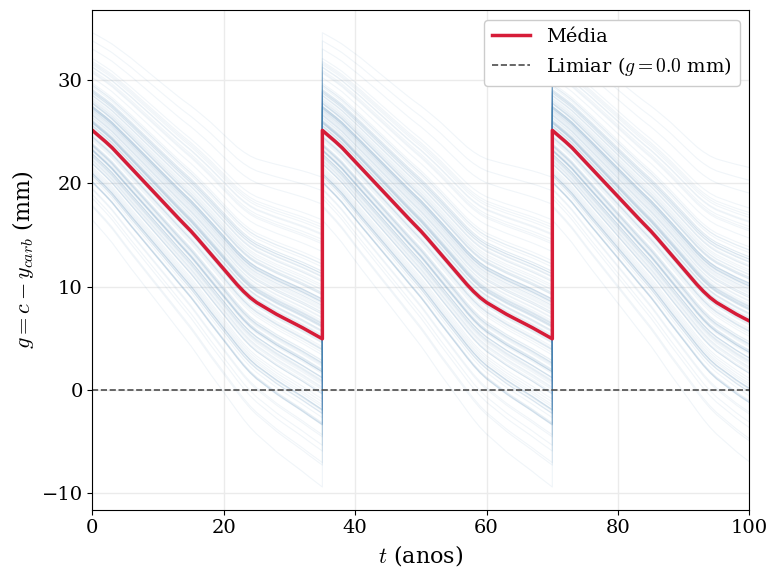

In [18]:
import matplotlib.pyplot as plt

# Configuração global de fontes para corresponder ao padrão académico (Serif/LaTeX)
plt.rcParams.update({
    'font.family': 'serif',
    'mathtext.fontset': 'cm',
    'font.size': 14,
    'axes.labelsize': 16,
    'legend.fontsize': 14,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14
})

plt.figure(figsize=(8, 6))

# Lnhas de dispersão
np.random.seed(42)
amostras_plot = np.random.choice(final_samples.shape[0], 150, replace=False)

for i in amostras_plot:
    plt.plot(final_lambda_df['Time (years)'], final_samples[i, :], color='steelblue', alpha=0.08, linewidth=0.8)

# Linha média a vermelho (crimson)
sample_mean = final_samples.mean(axis=0)
plt.plot(final_lambda_df['Time (years)'], sample_mean, color='#D61C38', linewidth=2.5, label='Média')

plt.axhline(y=g_limit, color='#4D4D4D', linestyle='--', linewidth=1.2, label=f'Limiar ($g = {g_limit}$ mm)')

plt.xlabel(r'$t$ (anos)')
plt.ylabel(r'$g = c - y_{carb}$ (mm)')
plt.xlim(0, t_total)
plt.grid(True, linestyle='-', color='#EBEBEB', linewidth=1.0)
plt.legend(loc='upper right', framealpha=1.0, edgecolor='#CCCCCC')

plt.tight_layout()
plt.show()